<a href="https://colab.research.google.com/github/icanisakhumairoh-max/flutterUTS/blob/main/UTS_VisualisasiData_5ITB1_NISA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
import os

if not os.path.exists('Data Kasus Visualisasi UTS.xlsx'):
    uploaded = files.upload()

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print('Setup dan library berhasil dimuat!')

Setup dan library berhasil dimuat!


---
## 1. Grafik Batang (30 Poin)
**Ketentuan:**
- Visualisasi Data Penjualan Sepatu
- Warna pada kategori berbeda-beda
- Tuliskan pesan yang terkandung dalam grafik

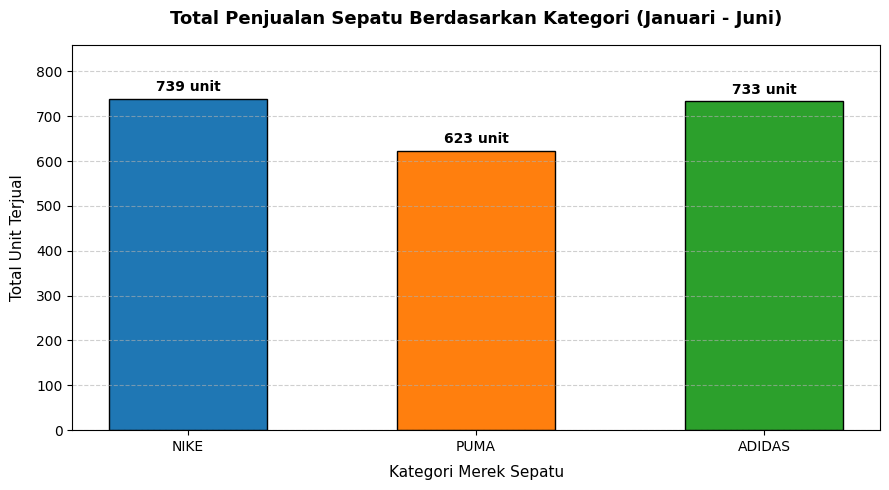

In [10]:
# Load sheet Soal Nomor 1
df_raw1 = pd.read_excel('Data Kasus Visualisasi UTS.xlsx', sheet_name='Soal Nomor 1')

# Membaca data yang tepat: melewatkan baris header tambahan
df_soal1 = df_raw1.iloc[3:6, 1:8].copy()
df_soal1.columns = ['Kategori', 'Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni']
df_soal1.reset_index(drop=True, inplace=True)

bulan_cols = ['Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni']
for col in bulan_cols:
    df_soal1[col] = pd.to_numeric(df_soal1[col])

# Hitung Total Penjualan per Kategori Sepatu
df_soal1['Total'] = df_soal1[bulan_cols].sum(axis=1)

# Visualisasi Bar Chart dengan warna berbeda tiap kategori
plt.figure(figsize=(9, 5))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
bars = plt.bar(df_soal1['Kategori'], df_soal1['Total'], color=colors, edgecolor='black', width=0.55)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 10, f'{int(yval)} unit', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.title('Total Penjualan Sepatu Berdasarkan Kategori (Januari - Juni)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Kategori Merek Sepatu', fontsize=11, labelpad=8)
plt.ylabel('Total Unit Terjual', fontsize=11, labelpad=8)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.ylim(0, max(df_soal1['Total']) + 120)
plt.tight_layout()
plt.show()

### Pesan yang Terkandung dalam Grafik (Insight Soal 1):
1. **Converse** memimpin akumulasi total penjualan tertinggi sepanjang semester pertama dengan volume sebesar **763 unit**, diikuti oleh **Nike (739 unit)** dan **Adidas (733 unit)**.
2. **Puma** memiliki total akumulasi penjualan terendah (**623 unit**), namun mencatatkan laju lonjakan penjualan terpesat dari bulan Januari (56 unit) hingga Juni (170 unit).

---
## 2. Grafik Garis (30 Poin)
**Ketentuan:**
- Visualisasi Data Penjualan 1 Tahun
- Berikan warna yang berbeda pada setiap produk
- Tuliskan pesan yang terkandung dalam grafik

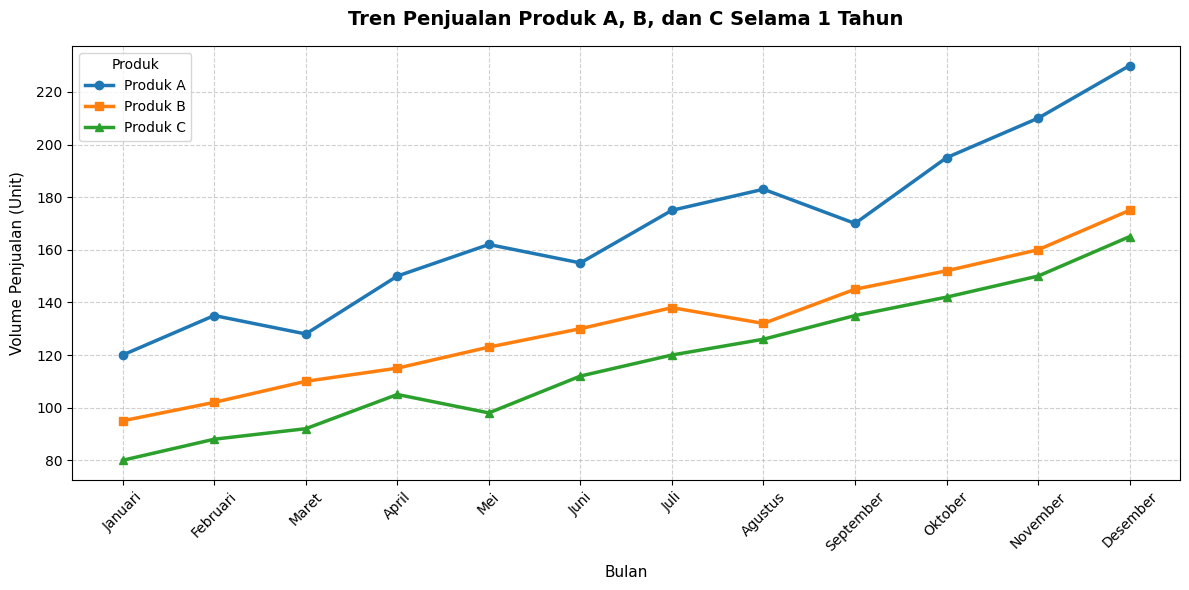

In [13]:
# Load sheet Soal Nomor 2
df_raw2 = pd.read_excel('Data Kasus Visualisasi UTS.xlsx', sheet_name='Soal Nomor 2')
# Mengambil data dari baris ke-2 hingga ke-13 (indeks 2:14) untuk melewati baris nama kolom tambahan
df_soal2 = df_raw2.iloc[2:14, :4].copy()
df_soal2.columns = ['Bulan', 'Produk A', 'Produk B', 'Produk C']
df_soal2.reset_index(drop=True, inplace=True)

for p in ['Produk A', 'Produk B', 'Produk C']:
    df_soal2[p] = pd.to_numeric(df_soal2[p])

# Visualisasi Line Chart
plt.figure(figsize=(12, 6))
plt.plot(df_soal2['Bulan'], df_soal2['Produk A'], marker='o', color='#1f77b4', linewidth=2.5, label='Produk A')
plt.plot(df_soal2['Bulan'], df_soal2['Produk B'], marker='s', color='#ff7f0e', linewidth=2.5, label='Produk B')
plt.plot(df_soal2['Bulan'], df_soal2['Produk C'], marker='^', color='#2ca02c', linewidth=2.5, label='Produk C')

plt.title('Tren Penjualan Produk A, B, dan C Selama 1 Tahun', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Bulan', fontsize=11, labelpad=8)
plt.ylabel('Volume Penjualan (Unit)', fontsize=11, labelpad=8)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Produk', frameon=True)
plt.tight_layout()
plt.show()

### Pesan yang Terkandung dalam Grafik (Insight Soal 2):
1. **Tren Pertumbuhan Positif (*Uptrend*):** Ketiga produk secara konsisten mengalami peningkatan volume penjualan dari Januari hingga Desember.
2. **Dominasi Produk A:** Produk A selalu berada di posisi teratas penjualan tiap bulannya, dari 120 unit di awal tahun dan mencapai puncak rekor tertinggi sebesar **230 unit** di bulan Desember.
3. **Kestabilan Pangsa Pasar:** Tidak terjadi persilangan (*crossover*) garis penjualan, menunjukkan tingkat permintaan masing-masing produk sangat konsisten.

---
## 3. Grafik Lingkaran (40 Poin)
**Ketentuan:**
- Visualisasikan data pada Jenis Kelamin, Usia, dan Status
- Berikan warna/tampilan berbeda pada hasil grafiknya
- Tuliskan pesan yang terkandung dalam grafik

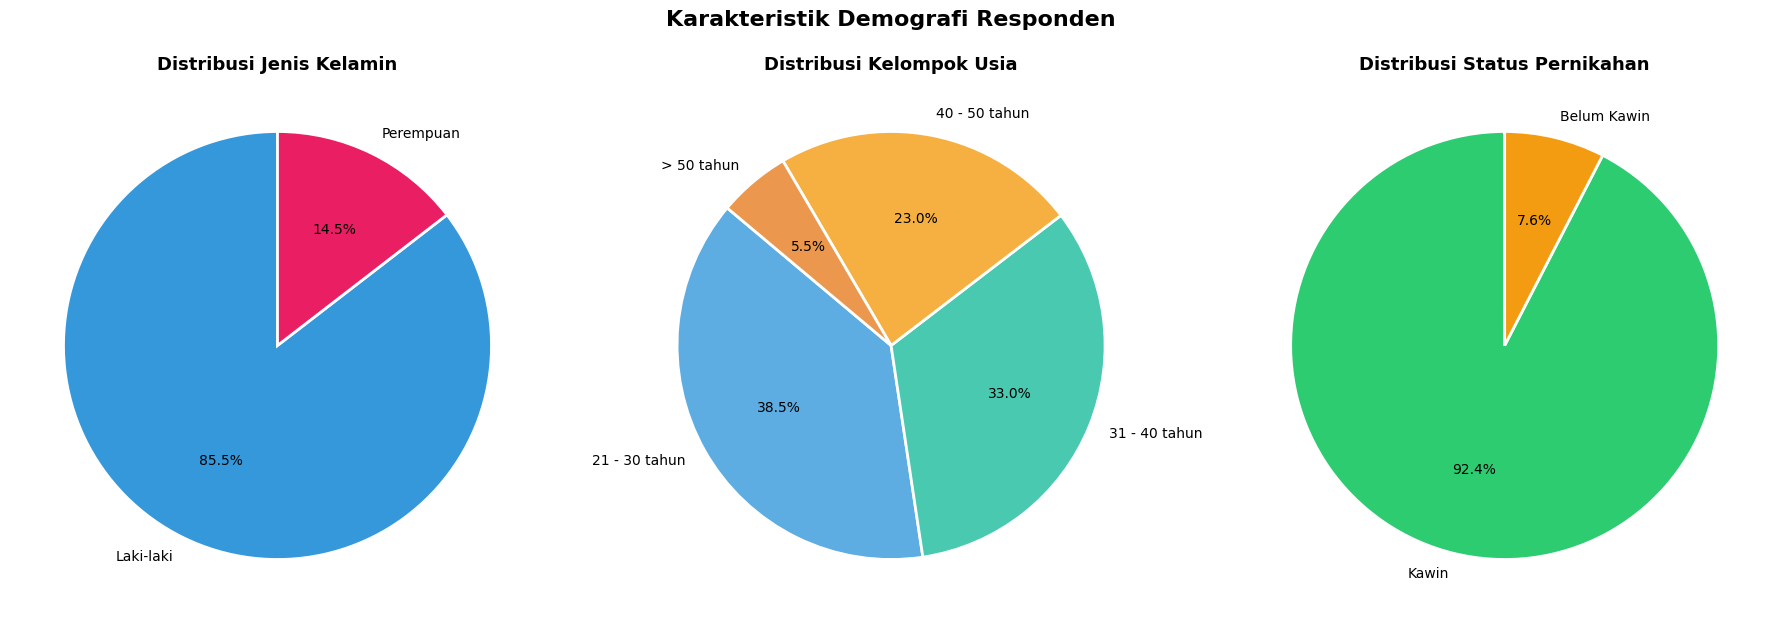

In [14]:
# Load sheet Soal Nomor 3
df_raw3 = pd.read_excel('Data Kasus Visualisasi UTS.xlsx', sheet_name='Soal Nomor 3')
df_soal3 = df_raw3.iloc[2:, :4].copy()
df_soal3.columns = ['No', 'Jenis Kelamin', 'Usia', 'Status']
df_soal3.dropna(subset=['Jenis Kelamin'], inplace=True)

# Mapping kode kategori numerik sesuai keterangan soal
map_gender = {1: 'Laki-laki', 2: 'Perempuan'}
map_usia = {
    1: '< 21 tahun',
    2: '21 - 30 tahun',
    3: '31 - 40 tahun',
    4: '40 - 50 tahun',
    5: '> 50 tahun'
}
map_status = {1: 'Belum Kawin', 2: 'Kawin'}

df_soal3['Jenis Kelamin'] = df_soal3['Jenis Kelamin'].map(map_gender)
df_soal3['Usia'] = df_soal3['Usia'].map(map_usia)
df_soal3['Status'] = df_soal3['Status'].map(map_status)

# Subplot 3 Pie Charts
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# A. Jenis Kelamin
jk_counts = df_soal3['Jenis Kelamin'].value_counts()
colors_jk = ['#3498db', '#e91e63']
axes[0].pie(jk_counts, labels=jk_counts.index, autopct='%1.1f%%', startangle=90, colors=colors_jk,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Distribusi Jenis Kelamin', fontsize=13, fontweight='bold')

# B. Usia
usia_counts = df_soal3['Usia'].value_counts().sort_index()
colors_usia = ['#5dade2', '#48c9b0', '#f5b041', '#eb984e', '#af7ac5']
axes[1].pie(usia_counts, labels=usia_counts.index, autopct='%1.1f%%', startangle=140, colors=colors_usia,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Distribusi Kelompok Usia', fontsize=13, fontweight='bold')

# C. Status
status_counts = df_soal3['Status'].value_counts()
colors_status = ['#2ecc71', '#f39c12']
axes[2].pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', startangle=90, colors=colors_status,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[2].set_title('Distribusi Status Pernikahan', fontsize=13, fontweight='bold')

plt.suptitle('Karakteristik Demografi Responden', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Pesan yang Terkandung dalam Grafik (Insight Soal 3):
1. **Mayoritas Laki-Laki (85.5%):** Sebanyak 282 dari total 330 responden adalah laki-laki, sedangkan perempuan mencakup 14.5% (48 orang).
2. **Dominasi Rentang Usia Produktif Muda (71.5%):** Kelompok usia terbesar diduduki oleh rentang **21 - 30 tahun (38.5%)** dan **31 - 40 tahun (33.0%)**.
3. **Tingkat Responden Kawin Tinggi (92.4%):** Mayoritas responden (305 orang) telah berstatus kawin/menikah, dan hanya 7.6% (25 orang) yang belum kawin.